In [ ]:
from pathlib import Path
import random
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import make_grid
import matplotlib.pyplot as plt

# Common Setup (Manual Page 3)
SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
out = Path("lab_outputs")
out.mkdir(exist_ok=True)
print("Device:", device)

# Step 1: Load and Scale Images to [-1, 1] (Manual Page 7)
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])
data = datasets.FashionMNIST("data", train=True, download=True, transform=transform)
loader = DataLoader(data, batch_size=128, shuffle=True)
print("Total Fashion-MNIST training images:", len(data))

In [2]:
# Step 2: Define Both Networks (Manual Page 7)
latent_dim = 64

G = nn.Sequential(
    nn.Linear(latent_dim, 256),
    nn.LeakyReLU(0.2),
    nn.Linear(256, 512),
    nn.LeakyReLU(0.2),
    nn.Linear(512, 784),
    nn.Tanh()
).to(device)

D = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, 512),
    nn.LeakyReLU(0.2),
    nn.Linear(512, 256),
    nn.LeakyReLU(0.2),
    nn.Linear(256, 1)
).to(device)

loss_fn = nn.BCEWithLogitsLoss()
opt_g = torch.optim.Adam(G.parameters(), lr=0.0002, betas=(0.5, 0.999))
opt_d = torch.optim.Adam(D.parameters(), lr=0.0002, betas=(0.5, 0.999))

fixed_z = torch.randn(25, latent_dim, device=device)

# Model Checkpoints Verification (Manual Page 7)
test_z = torch.randn(128, latent_dim, device=device)
fake_test = G(test_z)
logits_test = D(fake_test)
print("Noise batch shape:", test_z.shape)             # Expected: [128, 64]
print("Generator output shape:", fake_test.shape, "Range:", round(fake_test.min().item(), 2), "to", round(fake_test.max().item(), 2))
print("Discriminator output shape:", logits_test.shape) # Expected: [128, 1]

Noise batch shape: torch.Size([128, 64])
Generator output shape: torch.Size([128, 784]) Range: -0.52 to 0.46
Discriminator output shape: torch.Size([128, 1])


01 D=0.353 G=1.826


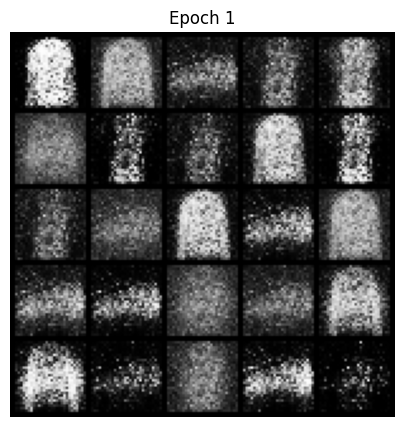

02 D=0.325 G=2.578
03 D=0.384 G=2.275
04 D=0.402 G=2.072
05 D=0.413 G=1.997


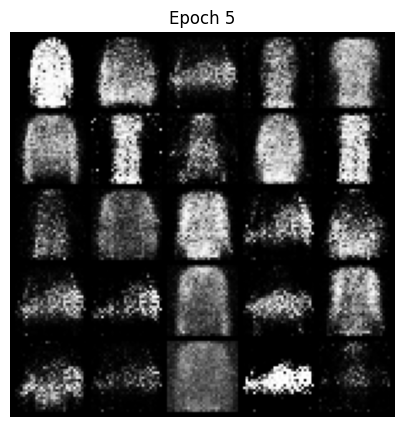

06 D=0.408 G=1.951
07 D=0.421 G=1.976
08 D=0.449 G=1.804
09 D=0.452 G=1.838
10 D=0.469 G=1.734


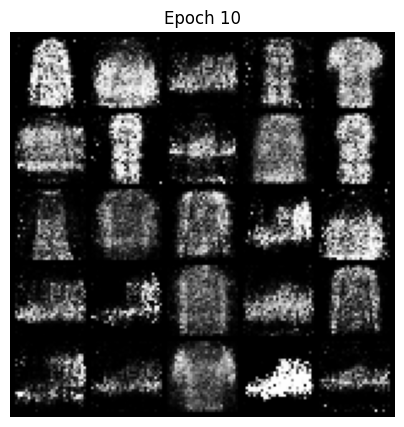

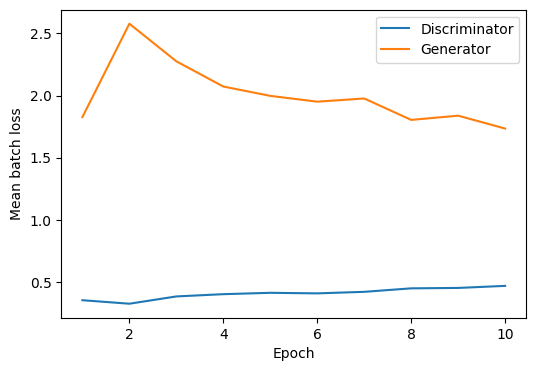

Saved generator checkpoint to lab_outputs/fashion_generator.pt


In [3]:
# Step 3 & Step 4: Adversarial Training & Evaluation (Manual Pages 8-9)
def generate_grid(epoch):
    with torch.no_grad():
        images = G(fixed_z).cpu().reshape(-1, 1, 28, 28)
        grid = make_grid((images + 1) / 2, nrow=5)
        plt.figure(figsize=(5, 5))
        plt.imshow(grid.permute(1, 2, 0))
        plt.title(f"Epoch {epoch}")
        plt.axis("off")
        plt.savefig(out / f"gan_epoch_{epoch:02d}.png", bbox_inches="tight")
        plt.show()

def train_batch(real):
    n = real.size(0)
    fake = G(torch.randn(n, latent_dim, device=device))

    # Discriminator update
    real_logits = D(real)
    fake_logits = D(fake.detach())
    d_loss = (loss_fn(real_logits, torch.ones_like(real_logits))
              + loss_fn(fake_logits, torch.zeros_like(fake_logits))) / 2
    opt_d.zero_grad()
    d_loss.backward()
    opt_d.step()

    # Generator update
    D.requires_grad_(False)
    opt_g.zero_grad()
    logits = D(fake)
    g_loss = loss_fn(logits, torch.ones_like(logits))
    g_loss.backward()
    opt_g.step()
    D.requires_grad_(True)

    return d_loss.item(), g_loss.item()

history = []
for epoch in range(1, 11):
    losses = [train_batch(real.to(device)) for real, _ in loader]
    avg_d, avg_g = [sum(values) / len(losses) for values in zip(*losses)]
    history.append((avg_d, avg_g))
    print(f"{epoch:02d} D={avg_d:.3f} G={avg_g:.3f}")
    if epoch in (1, 5, 10):
        generate_grid(epoch)

plt.figure(figsize=(6, 4))
plt.plot(range(1, 11), [d for d, g in history], label="Discriminator")
plt.plot(range(1, 11), [g for d, g in history], label="Generator")
plt.xlabel("Epoch")
plt.ylabel("Mean batch loss")
plt.legend()
plt.savefig(out / "gan_losses.png", bbox_inches="tight")
plt.show()

torch.save(G.state_dict(), out / "fashion_generator.pt")
print("Saved generator checkpoint to lab_outputs/fashion_generator.pt")